# Phase 3B Steps 5–6 — Numerical Hypothesis Testing

## Customer Retention Intelligence System

This independent notebook evaluates the three numerical hypotheses registered in Notebook
08. Welch's independent t-test is the primary mean-based method; Mann–Whitney U is a
complementary rank-distribution analysis. The comparison direction is always **churned minus
retained**.

All hypotheses, p-values, confidence intervals, and decisions are **exploratory and
unadjusted for multiple comparisons** because earlier EDA on these same development records
informed the questions. Results are not independent confirmation or causal evidence. Only
configured `development.parquet` is loaded. Analysis stops before categorical testing.

## 1. Independent setup and leakage-safe loading

The project root is detected from marker files, configuration is loaded with the existing
utility, and the configured development path is asserted before reading. Previous notebooks
are not executed or required for state.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.8g}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
target_column = config["data"]["target_column"]
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
numerical_hypotheses = {"HYP-01": "tenure", "HYP-02": "MonthlyCharges", "HYP-03": "TotalCharges"}
alpha = 0.05
family = "Numerical predictors versus churn"

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
assert df[list(numerical_hypotheses.values())].notna().all().all()
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Configured random state preserved: {random_state}; alpha={alpha}")
print(f"Development SHA-256: {source_sha256_before}")
display(df.head())

Development data: 5,634 rows × 21 columns
Configured random state preserved: 42; alpha=0.05
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.1,"5,475.9",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.35,212.3,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.45,137.1,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.75,"2,453.3",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86,"1,164.05",No


## 2. Exploratory hypotheses and estimands

For each predictor $X$, let group $Y$ be churned and group $N$ be retained.

**Mean hypothesis (primary Welch test)**

$$H_0^{mean}:\mu_Y-\mu_N=0,\qquad
H_1^{mean}:\mu_Y-\mu_N\ne0.$$

The estimand is the population mean difference in original units.

**Rank-distribution hypothesis (complementary Mann–Whitney analysis)**

$$H_0^{rank}:P(X_Y>X_N)+\tfrac12P(X_Y=X_N)=0.5,$$

against a two-sided departure. This targets relative ordering/stochastic tendency. It is not
generally a test of equal medians unless additional common-shape/location-shift conditions
hold. The registered questions are HYP-01 tenure, HYP-02 MonthlyCharges, and HYP-03
TotalCharges. Each belongs to the same numerical hypothesis family for later multiplicity
control; no correction is applied in this step.

## 3. Welch's independent t-test: primary analysis

For independent groups with possibly unequal variances,

$$t=\frac{\bar X_Y-\bar X_N}{\sqrt{s_Y^2/n_Y+s_N^2/n_N}},$$

with Welch–Satterthwaite degrees of freedom

$$\nu=\frac{(s_Y^2/n_Y+s_N^2/n_N)^2}
{(s_Y^2/n_Y)^2/(n_Y-1)+(s_N^2/n_N)^2/(n_N-1)}.$$

The two-sided 95% interval is
$\widehat\Delta\pm t_{.975,\nu}SE(\widehat\Delta)$. Notebook 10 found materially unequal
churn-group variances, so Welch is preferred to a pooled Student test and no redundant
Student test is implemented. Observations are nonnormal, tied, or bounded, but group sizes
of 1,495 and 4,139 make the sampling distribution of a finite-variance mean difference
approximately normal under independence. This does not repair dependence, selection bias,
confounding, or influential-tail problems.

In [3]:
# ruff: noqa: E501
def welch_analysis(churned, retained, confidence=0.95):
    y = np.asarray(churned, float); n = np.asarray(retained, float)
    y = y[np.isfinite(y)]; n = n[np.isfinite(n)]
    ny, nn = len(y), len(n)
    my, mn = y.mean(), n.mean()
    vy, vn = y.var(ddof=1), n.var(ddof=1)
    difference = my - mn
    se = np.sqrt(vy / ny + vn / nn)
    degrees_freedom = (vy / ny + vn / nn) ** 2 / ((vy / ny) ** 2 / (ny - 1) + (vn / nn) ** 2 / (nn - 1))
    t_statistic = difference / se
    p_value = 2 * stats.t.sf(abs(t_statistic), degrees_freedom)
    critical = stats.t.ppf((1 + confidence) / 2, degrees_freedom)
    scipy_result = stats.ttest_ind(y, n, equal_var=False, alternative="two-sided")
    return {"churned_n": ny, "retained_n": nn, "churned_mean": my, "retained_mean": mn, "churned_variance": vy, "retained_variance": vn, "mean_difference": difference, "standard_error": se, "welch_t": t_statistic, "welch_df": degrees_freedom, "welch_p": p_value, "ci_lower": difference - critical * se, "ci_upper": difference + critical * se, "scipy_t_check": scipy_result.statistic, "scipy_p_check": scipy_result.pvalue}


welch_rows = []
for hypothesis_id, predictor in numerical_hypotheses.items():
    churned = df.loc[df[target_column].eq("Yes"), predictor]
    retained = df.loc[df[target_column].eq("No"), predictor]
    row = {"hypothesis_id": hypothesis_id, "predictor": predictor, **welch_analysis(churned, retained)}
    row["decision_alpha_0.05"] = "Reject mean null (exploratory)" if row["welch_p"] < alpha else "Do not reject mean null"
    row["hypothesis_family"] = family
    welch_rows.append(row)
welch_results = pd.DataFrame(welch_rows)
display(welch_results)

,hypothesis_id,predictor,churned_n,retained_n,churned_mean,retained_mean,churned_variance,retained_variance,mean_difference,standard_error,welch_t,welch_df,welch_p,ci_lower,ci_upper,scipy_t_check,scipy_p_check,decision_alpha_0.05,hypothesis_family
0,HYP-01,tenure,1495,4139,17.955184,37.548925,381.66131,582.9393,-19.593741,0.62939055,-31.131292,"3,241.0015",2.2130625e-186,-20.827785,-18.359697,-31.131292,2.2130625e-186,Reject mean null (exploratory),Numerical predictors versus churn
1,HYP-02,MonthlyCharges,1495,4139,74.467659,61.624777,601.17679,966.21955,12.842882,0.797225,16.109483,"3,327.25",2.7933116e-56,11.279781,14.405983,16.109483,2.7933116e-56,Reject mean null (exploratory),Numerical predictors versus churn
2,HYP-03,TotalCharges,1495,4139,"1,529.8788","2,566.5015","3,556,482.2","5,489,606.6","-1,036.6226",60.870602,-17.029939,"3,258.5854",2.2778628e-62,"-1,155.9712",-917.27413,-17.029939,2.2778628e-62,Reject mean null (exploratory),Numerical predictors versus churn


## 4. Mann–Whitney U: complementary rank analysis

Mann–Whitney ranks pooled observations and evaluates relative ordering. SciPy's asymptotic
two-sided implementation applies tie correction and continuity correction. For churned as
group 1,

$$A=P(X_Y>X_N)+\tfrac12P(X_Y=X_N)=\frac{U_Y}{n_Yn_N},$$

is the tie-aware probability of superiority. Cliff's delta is

$$\delta=2A-1,$$

from −1 (churned always lower) through 0 (no ordering tendency) to +1 (churned always
higher). This complements rather than replaces Welch: a mean contrast can be driven by
different aspects of the distribution than a rank contrast.

In [4]:
# ruff: noqa: E501
def mann_whitney_analysis(churned, retained):
    y = np.asarray(churned, float); n = np.asarray(retained, float)
    y = y[np.isfinite(y)]; n = n[np.isfinite(n)]
    result = stats.mannwhitneyu(y, n, alternative="two-sided", method="asymptotic", use_continuity=True)
    ny, nn = len(y), len(n)
    superiority = result.statistic / (ny * nn)
    cliffs_delta = 2 * superiority - 1
    combined = np.concatenate([y, n])
    _, tie_counts = np.unique(combined, return_counts=True)
    total = ny + nn
    tie_term = np.sum(tie_counts**3 - tie_counts)
    variance_u = ny * nn / 12 * ((total + 1) - tie_term / (total * (total - 1)))
    z_absolute = max(0.0, abs(result.statistic - ny * nn / 2) - 0.5) / np.sqrt(variance_u)
    log_two_sided_p = np.log(2.0) + stats.norm.logsf(z_absolute)
    return {"mann_whitney_u_churned": result.statistic, "mann_whitney_p": result.pvalue, "mann_whitney_log10_p": log_two_sided_p / np.log(10), "probability_of_superiority_churned": superiority, "cliffs_delta": cliffs_delta, "tie_correction_applied": bool(np.any(tie_counts > 1)), "asymptotic_z_absolute": z_absolute}


rank_rows = []
for hypothesis_id, predictor in numerical_hypotheses.items():
    churned = df.loc[df[target_column].eq("Yes"), predictor]
    retained = df.loc[df[target_column].eq("No"), predictor]
    row = {"hypothesis_id": hypothesis_id, "predictor": predictor, **mann_whitney_analysis(churned, retained)}
    row["decision_alpha_0.05"] = "Reject rank null (exploratory)" if row["mann_whitney_p"] < alpha else "Do not reject rank null"
    row["hypothesis_family"] = family
    rank_rows.append(row)
mann_whitney_results = pd.DataFrame(rank_rows)
display(mann_whitney_results)

,hypothesis_id,predictor,mann_whitney_u_churned,mann_whitney_p,mann_whitney_log10_p,probability_of_superiority_churned,cliffs_delta,tie_correction_applied,asymptotic_z_absolute,decision_alpha_0.05,hypothesis_family
0,HYP-01,tenure,"1,611,207",1.0030357e-166,-165.99868,0.26038426,-0.47923149,True,27.520322,Reject rank null (exploratory),Numerical predictors versus churn
1,HYP-02,MonthlyCharges,"3,821,718",1.5222794e-41,-40.817506,0.61762095,0.2352419,True,13.501981,Reject rank null (exploratory),Numerical predictors versus churn
2,HYP-03,TotalCharges,"2,156,229",8.987968e-68,-67.046338,0.34846428,-0.30307144,True,17.395094,Reject rank null (exploratory),Numerical predictors versus churn


## 5. Minimum sufficient effect-size analysis

The raw mean difference preserves business units. Cohen's $d$ standardizes that contrast by
the pooled sample standard deviation,

$$s_p=\sqrt{\frac{(n_Y-1)s_Y^2+(n_N-1)s_N^2}{n_Y+n_N-2}},\qquad
d=\frac{\bar X_Y-\bar X_N}{s_p}.$$

Pooled $d$ is a descriptive standardization, not a claim of equal variances; when spreads
differ, its single denominator can obscure group-specific variability. Cliff's $\delta$ is
unit-free and rank-based, naturally incorporating ties. Conventional small/medium/large
labels are rough communication aids, not universal business thresholds. Statistical
significance depends heavily on sample size; practical importance requires original units,
uncertainty, overlap, operational cost, and domain context.

In [5]:
# ruff: noqa: E501
effect_rows = []
for hypothesis_id, predictor in numerical_hypotheses.items():
    w = welch_results.loc[welch_results["hypothesis_id"].eq(hypothesis_id)].iloc[0]
    r = mann_whitney_results.loc[mann_whitney_results["hypothesis_id"].eq(hypothesis_id)].iloc[0]
    pooled_sd = np.sqrt(((w["churned_n"] - 1) * w["churned_variance"] + (w["retained_n"] - 1) * w["retained_variance"]) / (w["churned_n"] + w["retained_n"] - 2))
    effect_rows.append({"hypothesis_id": hypothesis_id, "predictor": predictor, "raw_mean_difference_churned_minus_retained": w["mean_difference"], "pooled_standard_deviation": pooled_sd, "cohens_d": w["mean_difference"] / pooled_sd, "cliffs_delta": r["cliffs_delta"], "probability_of_superiority_churned": r["probability_of_superiority_churned"]})
effect_sizes = pd.DataFrame(effect_rows)
display(effect_sizes)

,hypothesis_id,predictor,raw_mean_difference_churned_minus_retained,pooled_standard_deviation,cohens_d,cliffs_delta,probability_of_superiority_churned
0,HYP-01,tenure,-19.593741,23.011873,-0.85146223,-0.47923149,0.26038426
1,HYP-02,MonthlyCharges,12.842882,29.48533,0.43556854,0.2352419,0.61762095
2,HYP-03,TotalCharges,"-1,036.6226","2,230.8758",-0.46467071,-0.30307144,0.34846428


## 6. Consolidated exploratory results

Very small p-values are shown in scientific notation. If a floating-point p-value underflows
to zero, the display reports underflow and the independently computed log10 p-value rather
than claiming a mathematically exact zero. Welch remains the primary analysis; Mann–Whitney
remains complementary. Confidence intervals use the same formula and direction as Notebook
09 and are cross-checked numerically below.

In [6]:
# ruff: noqa: E501
def format_p_value(value, log10_value=None):
    if value == 0:
        return f"underflow (<{np.nextafter(0, 1):.2e}); log10(p)≈{log10_value:.2f}"
    return f"{value:.6e}"


interpretations = {
    "tenure": "Churned customers have substantially shorter average tenure and a strong lower-rank tendency; lifecycle association is practically material but not causal.",
    "MonthlyCharges": "Churned customers have moderately higher average monthly charges and tend to rank higher, with substantial distribution overlap.",
    "TotalCharges": "Churned customers have lower accumulated charges, largely compatible with shorter tenure; the marginal contrast is structurally confounded by lifecycle.",
}
consolidated_rows = []
for hypothesis_id, predictor in numerical_hypotheses.items():
    w = welch_results.loc[welch_results["hypothesis_id"].eq(hypothesis_id)].iloc[0]
    r = mann_whitney_results.loc[mann_whitney_results["hypothesis_id"].eq(hypothesis_id)].iloc[0]
    e = effect_sizes.loc[effect_sizes["hypothesis_id"].eq(hypothesis_id)].iloc[0]
    consolidated_rows.append({"hypothesis_id": hypothesis_id, "predictor": predictor, "primary_method": "Welch independent t-test", "mean_difference_churned_minus_retained": w["mean_difference"], "welch_t": w["welch_t"], "welch_df": w["welch_df"], "welch_p_raw": w["welch_p"], "welch_p_display": format_p_value(w["welch_p"]), "ci_95_lower": w["ci_lower"], "ci_95_upper": w["ci_upper"], "cohens_d": e["cohens_d"], "complementary_method": "Mann–Whitney U (asymptotic, tie-corrected)", "mann_whitney_u": r["mann_whitney_u_churned"], "mann_whitney_p_raw": r["mann_whitney_p"], "mann_whitney_p_display": format_p_value(r["mann_whitney_p"], r["mann_whitney_log10_p"]), "cliffs_delta": r["cliffs_delta"], "exploratory_decision": w["decision_alpha_0.05"], "statistical_and_practical_interpretation": interpretations[predictor], "hypothesis_family": family, "multiplicity_status": "Unadjusted; correction deferred"})
consolidated_results = pd.DataFrame(consolidated_rows)
display(consolidated_results)

display(Markdown(
    "### Actual-result summary\n\n"
    + "\n".join(
        f"- **{row.hypothesis_id} — {row.predictor}:** mean difference {row.mean_difference_churned_minus_retained:+.3f}, 95% CI [{row.ci_95_lower:.3f}, {row.ci_95_upper:.3f}], Welch t({row.welch_df:.1f})={row.welch_t:.3f}, p={row.welch_p_display}; Cohen’s d={row.cohens_d:+.3f}; U={row.mann_whitney_u:,.0f}, rank p={row.mann_whitney_p_display}, Cliff’s δ={row.cliffs_delta:+.3f}."
        for _, row in consolidated_results.iterrows()
    )
))

,hypothesis_id,predictor,primary_method,mean_difference_churned_minus_retained,welch_t,welch_df,welch_p_raw,welch_p_display,ci_95_lower,ci_95_upper,cohens_d,complementary_method,mann_whitney_u,mann_whitney_p_raw,mann_whitney_p_display,cliffs_delta,exploratory_decision,statistical_and_practical_interpretation,hypothesis_family,multiplicity_status
0,HYP-01,tenure,Welch independent t-test,-19.593741,-31.131292,"3,241.0015",2.2130625e-186,2.213062e-186,-20.827785,-18.359697,-0.85146223,"Mann–Whitney U (asymptotic, tie-corrected)","1,611,207",1.0030357e-166,1.003036e-166,-0.47923149,Reject mean null (exploratory),Churned customers have substantially shorter a...,Numerical predictors versus churn,Unadjusted; correction deferred
1,HYP-02,MonthlyCharges,Welch independent t-test,12.842882,16.109483,"3,327.25",2.7933116e-56,2.793312e-56,11.279781,14.405983,0.43556854,"Mann–Whitney U (asymptotic, tie-corrected)","3,821,718",1.5222794e-41,1.522279e-41,0.2352419,Reject mean null (exploratory),Churned customers have moderately higher avera...,Numerical predictors versus churn,Unadjusted; correction deferred
2,HYP-03,TotalCharges,Welch independent t-test,"-1,036.6226",-17.029939,"3,258.5854",2.2778628e-62,2.277863e-62,"-1,155.9712",-917.27413,-0.46467071,"Mann–Whitney U (asymptotic, tie-corrected)","2,156,229",8.987968e-68,8.987968e-68,-0.30307144,Reject mean null (exploratory),Churned customers have lower accumulated charg...,Numerical predictors versus churn,Unadjusted; correction deferred


### Actual-result summary

- **HYP-01 — tenure:** mean difference -19.594, 95% CI [-20.828, -18.360], Welch t(3241.0)=-31.131, p=2.213062e-186; Cohen’s d=-0.851; U=1,611,207, rank p=1.003036e-166, Cliff’s δ=-0.479.
- **HYP-02 — MonthlyCharges:** mean difference +12.843, 95% CI [11.280, 14.406], Welch t(3327.2)=16.109, p=2.793312e-56; Cohen’s d=+0.436; U=3,821,718, rank p=1.522279e-41, Cliff’s δ=+0.235.
- **HYP-03 — TotalCharges:** mean difference -1036.623, 95% CI [-1155.971, -917.274], Welch t(3258.6)=-17.030, p=2.277863e-62; Cohen’s d=-0.465; U=2,156,229, rank p=8.987968e-68, Cliff’s δ=-0.303.

## 7. Essential new visualizations

Only three inference-focused views are added: mean-difference intervals on separate scales,
pooled-standardized mean effects, and rank effects. Distribution plots were already covered
in earlier notebooks and are intentionally not repeated.

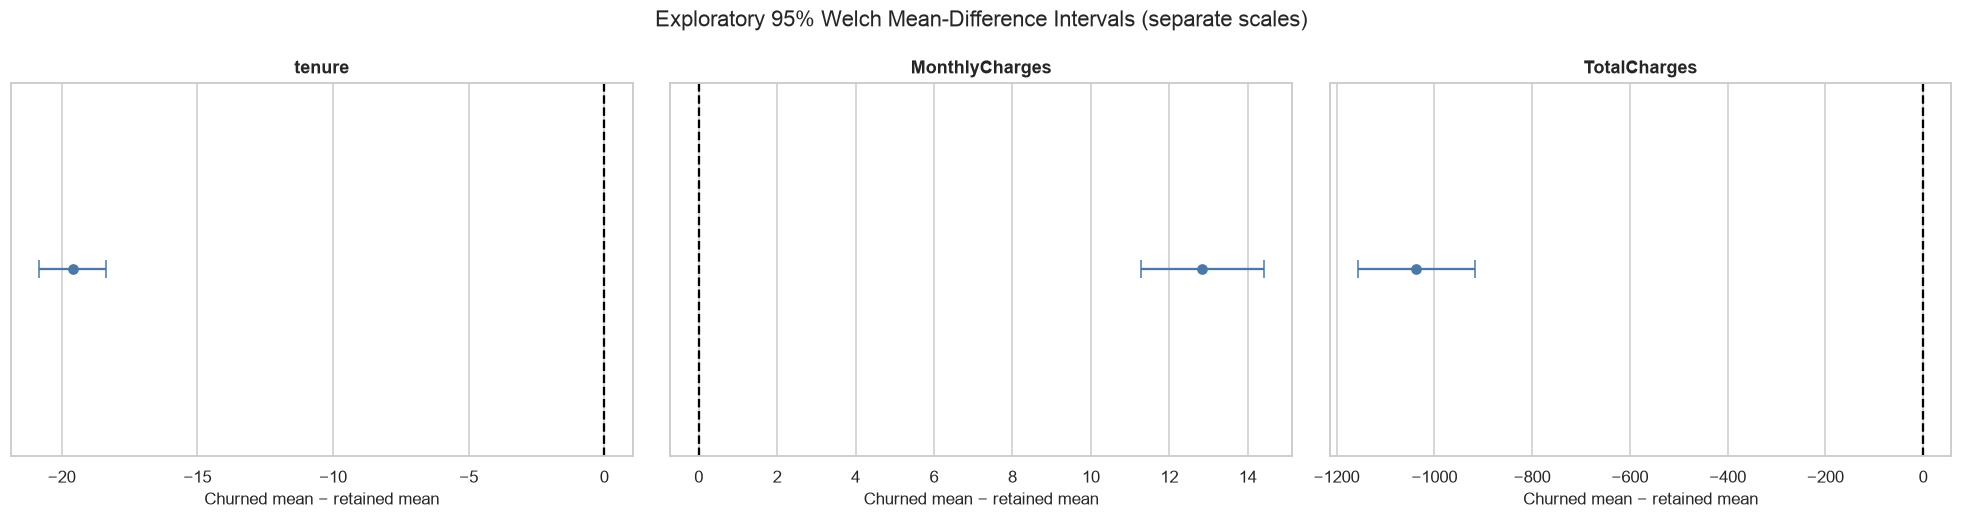

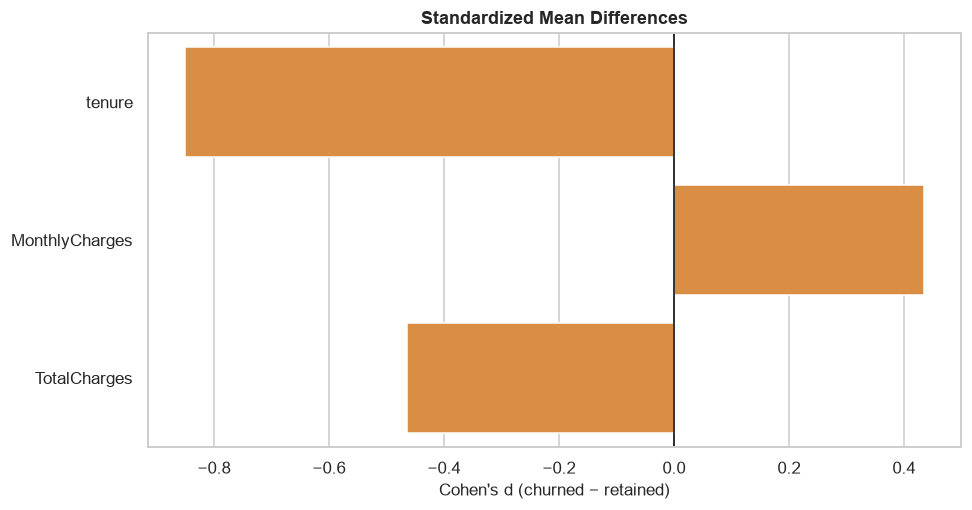

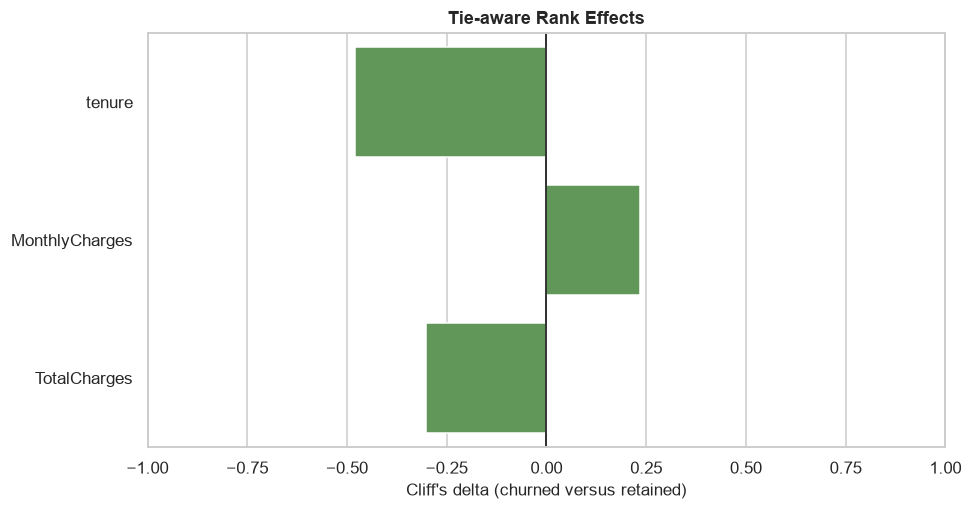

In [7]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for axis, (_, row) in zip(axes, consolidated_results.iterrows(), strict=True):
    estimate = row["mean_difference_churned_minus_retained"]
    axis.errorbar(estimate, [0], xerr=[[estimate - row["ci_95_lower"]], [row["ci_95_upper"] - estimate]], fmt="o", capsize=6, color="#4C78A8")
    axis.axvline(0, color="black", linestyle="--")
    axis.set(title=row["predictor"], xlabel="Churned mean − retained mean", yticks=[])
fig.suptitle("Exploratory 95% Welch Mean-Difference Intervals (separate scales)")
fig.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=effect_sizes, x="cohens_d", y="predictor", color="#F28E2B", ax=axis)
axis.axvline(0, color="black", linewidth=1)
axis.set(title="Standardized Mean Differences", xlabel="Cohen's d (churned − retained)", ylabel="")
plt.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=effect_sizes, x="cliffs_delta", y="predictor", color="#59A14F", ax=axis)
axis.axvline(0, color="black", linewidth=1)
axis.set(title="Tie-aware Rank Effects", xlabel="Cliff's delta (churned versus retained)", ylabel="", xlim=(-1, 1))
plt.tight_layout()
plt.show()

## 8. Business and modelling implications

- **Lifecycle:** the negative tenure contrast is large in original and standardized terms.
  It supports lifecycle-aware retention analysis, but churn timing, contract, acquisition
  cohort, and service composition can confound the marginal association.
- **Monthly subscription charges:** churned customers average more per month, but broad
  overlap means price alone cannot identify churners. Product bundles and internet service
  mix are plausible explanations.
- **Accumulated expenditure:** lower TotalCharges among churners is compatible with their
  much shorter tenure. It is not evidence that lower cumulative spending causes churn.
- **Prediction:** association and effect magnitude may motivate candidate predictors, but
  they do not establish incremental predictive value after other variables, out-of-sample
  performance, calibration, stability, or causal actionability. No feature selection occurs.

With thousands of observations, even small effects can be statistically detectable. A
business decision should use raw magnitude, confidence interval, overlap, customer volume,
intervention cost, and evidence that an intervention changes outcomes—not p-values alone.

## 9. Interview questions with speakable answers

### Q1. Student's t-test versus Welch's t-test?

**Answer:** Both test mean differences. Student's independent t-test pools group variances
and assumes equal population variance. Welch uses separate variance estimates and adjusted
degrees of freedom, so it remains reliable with unequal variances and unequal group sizes.
Because it loses little efficiency when variances happen to be equal, Welch is a sensible
default here.

### Q2. Welch's t-test versus Mann–Whitney U?

**Answer:** Welch targets a difference in population means. Mann–Whitney targets relative
ranks or stochastic ordering. It is not automatically a median test and is not a drop-in
nonparametric version of Welch. I choose based on the business estimand and may report both
when mean and rank perspectives are independently useful.

### Q3. Statistical significance versus practical significance?

**Answer:** Statistical significance measures incompatibility with a null under a model and
depends strongly on sample size. Practical significance asks whether the magnitude matters
in business units after costs, overlap, uncertainty, and actionability. I report confidence
intervals and effect sizes, not only p-values.

### Q4. Cohen's d versus Cliff's delta?

**Answer:** Cohen's d standardizes a mean difference using a standard deviation and is
sensitive to means, tails, and the chosen pooled scale. Cliff's delta is rank-based: it is
the difference between probabilities that a churned value is higher versus lower than a
retained value, with ties handled. They answer related but different questions.

## 10. Assumptions and remaining limitations

1. Customer rows are assumed independent for both procedures; account, household,
   geographic, or temporal dependence is unavailable for assessment.
2. The source sampling mechanism and target population are unknown. Large samples reduce
   random error but do not fix selection bias.
3. Welch relies on finite variance and a large-sample mean approximation. Mann–Whitney's
   asymptotic calculation relies on independent groups and valid tie correction.
4. Pooled Cohen's d is only a descriptive standardization under unequal variances.
5. All three questions were EDA-informed, share a family, and are unadjusted in this step.
6. Marginal associations can reflect confounding and do not establish causality,
   intervention effect, or incremental model value.
7. No categorical hypothesis testing, multiple-group comparison, multiplicity correction,
   feature engineering, preprocessing, balancing, or modelling is performed.

## 11. Numerical, integrity, and leakage verification

The final cell checks manual calculations against SciPy, effect directions, rank identities,
Notebook 09 interval values, all ten prior notebook hashes, source checksum, and development-
only loading. Execution metadata may change between runs; seeded configuration and logical
numerical results are the reproducibility targets.

In [8]:
# ruff: noqa: E501
notebook_09_reference_ci = {
    "tenure": (-20.8277846, -18.3596968),
    "MonthlyCharges": (11.2797810, 14.4059826),
    "TotalCharges": (-1155.971162, -917.274126),
}
for _, row in welch_results.iterrows():
    expected = notebook_09_reference_ci[row["predictor"]]
    assert np.allclose([row["ci_lower"], row["ci_upper"]], expected, rtol=0, atol=1e-5)
    assert np.isclose(row["welch_t"], row["scipy_t_check"], rtol=1e-12)
    assert np.isclose(row["welch_p"], row["scipy_p_check"], rtol=1e-10)

expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
    "08_statistical_foundations.ipynb": "11578c2e7cfa07a3fb826601d7afb356c224443d6547f7dc93725b45ac6653f2",
    "09_confidence_interval_analysis.ipynb": "50bf2497adec4d4e5d09502b0849420c9e53d5383615152f51fbc71629fb61c3",
    "10_distribution_diagnostics.ipynb": "38341766a6a26f1c7ba03c521500d15eef0038efd9e01d7b6bf7468de0dd1b58",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert random_state == 42 and alpha == 0.05
assert welch_results["welch_p"].between(0, 1).all()
assert mann_whitney_results["mann_whitney_p"].between(0, 1).all()
assert mann_whitney_results["probability_of_superiority_churned"].between(0, 1).all()
assert effect_sizes["cliffs_delta"].between(-1, 1).all()
assert np.allclose(2 * mann_whitney_results["probability_of_superiority_churned"] - 1, mann_whitney_results["cliffs_delta"])
assert np.sign(effect_sizes["raw_mean_difference_churned_minus_retained"]).equals(np.sign(effect_sizes["cohens_d"]))
assert list(consolidated_results["hypothesis_id"]) == ["HYP-01", "HYP-02", "HYP-03"]
assert consolidated_results["hypothesis_family"].eq(family).all()

print("All numerical-test, effect-size, Notebook 09 agreement, integrity, and leakage checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All numerical-test, effect-size, Notebook 09 agreement, integrity, and leakage checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...
08_statistical_foundations.ipynb,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...
09_confidence_interval_analysis.ipynb,50bf2497adec4d4e5d09502b0849420c9e53d538361515...,50bf2497adec4d4e5d09502b0849420c9e53d538361515...
10_distribution_diagnostics.ipynb,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...
